# Zomato Exploratory Data Analysis Project 

## Step1 - Installing Matplotlib & Seaborn Library 

In [ ]:
!pip install matplotlib

In [ ]:
!pip install seaborn

## Step 2 - Importing all the required Libraries

In [3]:
import numpy as np                   # it perform numerical operations
import pandas as pd                  # it perform data handle and cleaning
import matplotlib.pyplot as plt      # it perform to create graphs
import seaborn as sns                # it perform to create attract to statistical chart 


## Step 3 - Loading The Dataset

In [5]:
df = pd.read_csv("zomato_data.csv")
df

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet
...,...,...,...,...,...,...,...
143,Melting Melodies,No,No,3.3/5,0,100,Dining
144,New Indraprasta,No,No,3.3/5,0,150,Dining
145,Anna Kuteera,Yes,No,4.0/5,771,450,Dining
146,Darbar,No,No,3.0/5,98,800,Dining


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Restaurant Name              148 non-null    str  
 1   Online_Order                 148 non-null    str  
 2   Book_Table                   148 non-null    str  
 3   Rate                         148 non-null    str  
 4   Votes                        148 non-null    int64
 5   Approx_Cost(For Two People)  148 non-null    int64
 6   Listed_In(Type)              148 non-null    str  
dtypes: int64(2), str(5)
memory usage: 12.7 KB


## Step 4 - Data Cleaning

### 1 Convert The Rate Column To a Numeric DataType

In [11]:
def handleRate(value):
    value = str(value).split('/')
    value = value[0]
    return float(value)
df['Rate'] = df['Rate'].apply(handleRate)
print(df.head(5))

         Restaurant Name Online_Order Book_Table  Rate  Votes  \
0                  Jalsa          Yes        Yes   4.1    775   
1         Spice Elephant          Yes         No   4.1    787   
2        San Churro Cafe          Yes         No   3.8    918   
3  Addhuri Udupi Bhojana           No         No   3.7     88   
4          Grand Village           No         No   3.8    166   

   Approx_Cost(For Two People) Listed_In(Type)  
0                          800          Buffet  
1                          800          Buffet  
2                          800          Buffet  
3                          300          Buffet  
4                          600          Buffet  


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Restaurant Name              148 non-null    str    
 1   Online_Order                 148 non-null    str    
 2   Book_Table                   148 non-null    str    
 3   Rate                         148 non-null    float64
 4   Votes                        148 non-null    int64  
 5   Approx_Cost(For Two People)  148 non-null    int64  
 6   Listed_In(Type)              148 non-null    str    
dtypes: float64(1), int64(2), str(4)
memory usage: 11.9 KB


### Standardize Column Names

In [14]:
df.columns = df.columns.str.lower()

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   restaurant name              148 non-null    str    
 1   online_order                 148 non-null    str    
 2   book_table                   148 non-null    str    
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    str    
dtypes: float64(1), int64(2), str(4)
memory usage: 11.9 KB


### Rename the Cost Column

In [24]:
df = df.rename(columns={
    'approx_cost(for two people)' : 'approx_cost',
})

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   restaurant name  148 non-null    str    
 1   online_order     148 non-null    str    
 2   book_table       148 non-null    str    
 3   rate             148 non-null    float64
 4   votes            148 non-null    int64  
 5   approx_cost      148 non-null    int64  
 6   listed_in(type)  148 non-null    str    
dtypes: float64(1), int64(2), str(4)
memory usage: 11.9 KB


### 4. Checking for Missing Values & Duplicate Records

In [29]:
print("Missing Values:")
print(df.isnull().sum())
print("Duplicated Rows:",df.duplicated().sum())

Missing Values:
restaurant name    0
online_order       0
book_table         0
rate               0
votes              0
approx_cost        0
listed_in(type)    0
dtype: int64
Duplicated Rows: 0


## Step 5 -Exploratory Data Analysis 

 ### 1. How many customer votes has each restaurant type received?

In [32]:
df.head()

,restaurant name,online_order,book_table,rate,votes,approx_cost,listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


In [33]:
grouped_data = df.groupby('listed_in(type)')['votes'].sum()
grouped_data

listed_in(type)
Buffet     3028
Cafes      6434
Dining    20363
other      9367
Name: votes, dtype: int64

### 2. How many restaurants offer table booking?


In [35]:
result = df['book_table' ].value_counts()
result

book_table
No     140
Yes      8
Name: count, dtype: int64

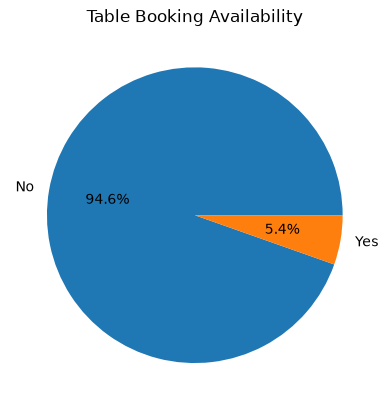

In [37]:
result.plot.pie(autopct = '%1.1f%%')
plt.title("Table Booking Availability")
plt.show()

### 3. Which five restaurants have the highest number of votes?

In [41]:
Top5 = df.nlargest(5, 'votes')
print(Top5[['restaurant name', 'votes']])

      restaurant name  votes
38  Empire Restaurant   4884
86      Meghana Foods   4401
7              Onesta   2556
44             Onesta   2556
65        Kabab Magic   1720


<function matplotlib.pyplot.show(close=None, block=None)>

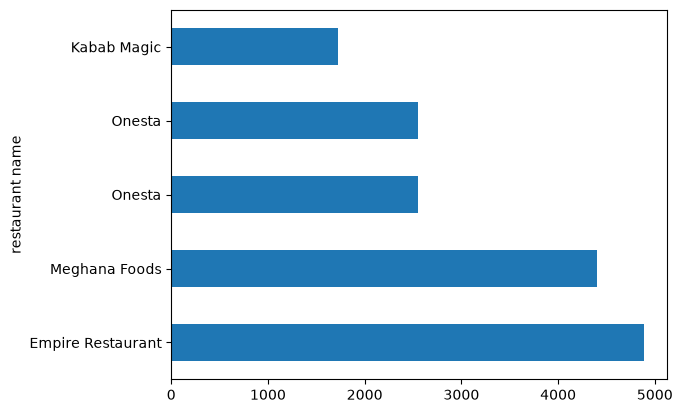

In [50]:
top5.plot.barh(x= 'restaurant name', y= 'votes', legend= False)
plt.show

### 4.Is there a relationship between restaurant ratings and customer votes?

In [51]:
df.head()

,restaurant name,online_order,book_table,rate,votes,approx_cost,listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


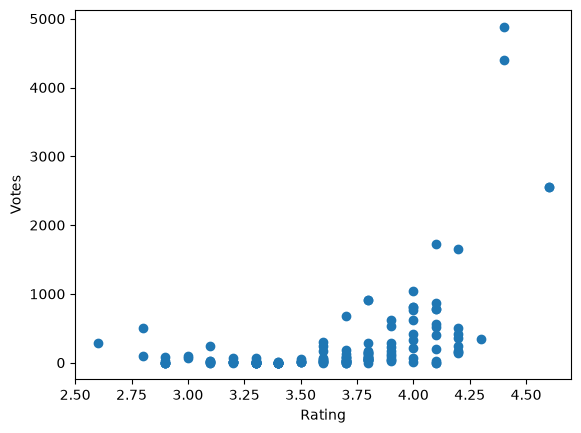

In [52]:
plt.scatter(df['rate'], df['votes'])
plt.xlabel("Rating")
plt.ylabel("Votes")
plt.show()

### 5. What is the average rating for each restaurant type?

In [53]:
result = df.groupby('listed_in(type)')['rate' ].mean()
print(result.sort_values(ascending=False))

listed_in(type)
other     3.912500
Buffet    3.842857
Cafes     3.765217
Dining    3.571818
Name: rate, dtype: float64


### 6. What type of restaurant do the majority of customers order from? 1

Text(0, 0.5, 'count of Restaurant')

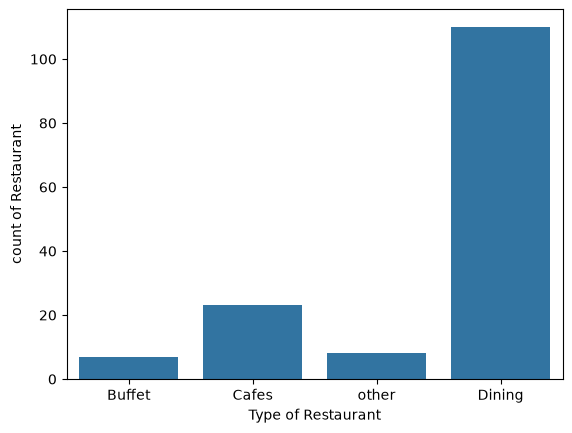

In [54]:
sns.countplot(x=df['listed_in(type)'])
plt.xlabel("Type of Restaurant")
plt.ylabel("count of Restaurant")

### 7. What ratings do restaurants most commonly receive?

<function matplotlib.pyplot.show(close=None, block=None)>

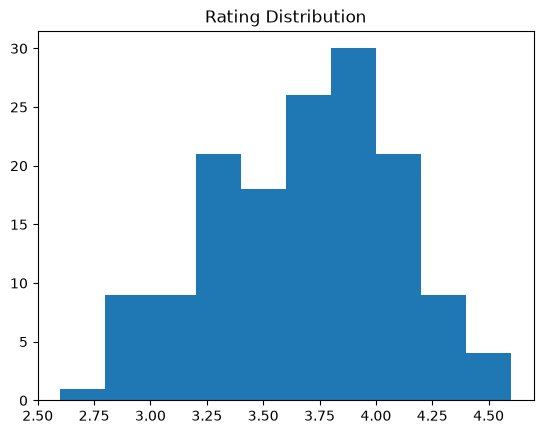

In [57]:
plt.hist(df['rate'],bins=10)
plt.title("Rating Distribution")
plt.show

### 8. Which restaurant type has the highest average cost for two people?


In [58]:
result = df.groupby('listed_in(type)') ['approx_cost' ].mean()
result.sort_values(ascending= False)

listed_in(type)
Buffet    671.428571
other     668.750000
Cafes     545.652174
Dining    357.272727
Name: approx_cost, dtype: float64

###  9. Which order mode - online or offline - gets better ratings?

In [59]:
df.head()

,restaurant name,online_order,book_table,rate,votes,approx_cost,listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


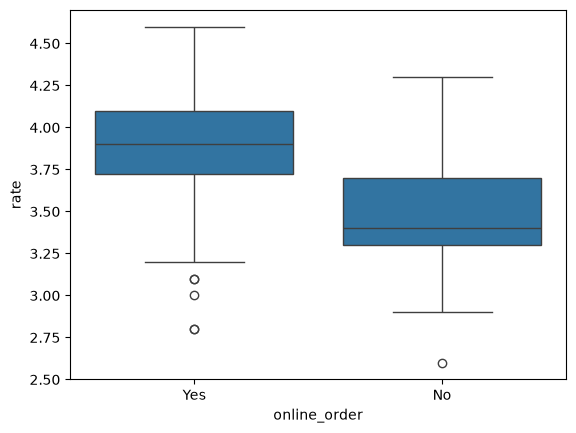

In [60]:
sns.boxplot(x ='online_order', y='rate', data = df)
plt.show()

### 10. Which restaurant types have more offline-ordering records?